# A reproducible benchmark of visual QA, counting, spatial reasoning, caption alignment and consistency


**Central hypothesis.** Strong performance on general image descriptions need not imply dependable counting, relational reasoning or grounding. This is a hypothesis to test, not an assumed finding.

This notebook separates **controlled synthetic evaluation** from an **optional, real-image COCO evaluation**. Synthetic ground truth is generated from exact drawing instructions. COCO count ground truth is based on COCO annotations and its own visibility conventions. These are different populations and must not be pooled without careful interpretation.

**Models:** BLIP VQA (`Salesforce/blip-vqa-base`) for generative question answering and CLIP (`openai/clip-vit-base-patch32`) for caption ranking. Their task coverage differs. Unsupported cells in the leaderboard show N/A, not a score of zero.

**Getting started:** Colab → Runtime → Change runtime type → T4 GPU. Run cells from top to bottom. Model downloads need internet access. Default small evaluation is designed as a functional pilot, not a published accuracy estimate. Change `N_SCENES` and `RUN_COCO` once it works. Kaggle may require internet enabled or pre-attached model assets.

**Research questions**
1. How precisely does BLIP answer visually grounded questions?
2. Does counting accuracy vary with object density?
3. Are spatial relations, especially left/right, interpreted correctly?
4. Can CLIP reject minimally altered captions?
5. Are answers stable under paraphrasing and logically complementary relational questions?

**Evaluation validity:** Synthetic scenes are deliberately simple and do not establish natural-image performance. The default scenes are created programmatically and are **not** model-generated ground truth.

## 1. Environment and reproducibility
The notebook uses deterministic generation, fixed image sizes, and greedy decoding. GPU is strongly recommended. Versions and experiment settings are exported with the results. Package installation is isolated to one cell.

In [1]:
%pip -q install "transformers>=4.49,<5" "accelerate>=1.3,<2" "safetensors>=0.4" "pycocotools>=2.0.7" "scipy>=1.11" "seaborn>=0.13"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 614.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 51.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, io, json, random, time, sys, platform, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
import torch, transformers, requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
N_SCENES = 24                  # Pilot: 24 scenes; increase to 100-500 for follow-up
MAX_COUNT = 6
IMAGE_SIZE = 384
RUN_COCO = False              # Optional real-image evaluation in Section 12
COCO_IMAGE_LIMIT = 12
COCO_CATEGORIES = {"person", "dog", "cat", "car", "bicycle"}
MAX_NEW_TOKENS = 12
OUT = Path('/content/vlm_benchmark_outputs') if Path('/content').exists() else Path('./vlm_benchmark_outputs')
OUT.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
sns.set_theme(style='whitegrid')
CONFIG = dict(seed=SEED, n_scenes=N_SCENES, max_count=MAX_COUNT, image_size=IMAGE_SIZE,
              run_coco=RUN_COCO, coco_image_limit=COCO_IMAGE_LIMIT, device=DEVICE,
              torch=torch.__version__, transformers=transformers.__version__,
              python=sys.version.split()[0], gpu=torch.cuda.get_device_name(0) if DEVICE=='cuda' else None)
print(json.dumps(CONFIG, indent=2))

{
  "seed": 42,
  "n_scenes": 24,
  "max_count": 6,
  "image_size": 384,
  "run_coco": false,
  "coco_image_limit": 12,
  "device": "cpu",
  "torch": "2.11.0+cpu",
  "transformers": "4.57.6",
  "python": "3.13.16",
  "gpu": null
}


## 2. Generate controlled visual scenes
Each scene contains a red circle, blue square, and between 1 and 6 **green triangles**. Their positions are constrained so the red circle and blue square have an unambiguous left/right and above/below ordering. Distractor captions differ by one object attribute or one spatial relation. The generated image labels are known exactly.

**Operational definitions:** left/right and above/below refer to the viewer's frame. Count questions ask only for green triangles. If more than one triangle appears, the caption states the exact count. Scenes are limited to colored geometric drawings rather than photographs, which is a deliberate limitation.

,image_id,image_path,source_dataset,count,horizontal,vertical,red_x,blue_x
0,synthetic_0000,/content/vlm_benchmark_outputs/scenes/scene_00...,synthetic_geometry,1,left,above,105,275
1,synthetic_0001,/content/vlm_benchmark_outputs/scenes/scene_00...,synthetic_geometry,2,right,above,275,105
2,synthetic_0002,/content/vlm_benchmark_outputs/scenes/scene_00...,synthetic_geometry,3,left,below,105,275
3,synthetic_0003,/content/vlm_benchmark_outputs/scenes/scene_00...,synthetic_geometry,4,right,below,275,105
4,synthetic_0004,/content/vlm_benchmark_outputs/scenes/scene_00...,synthetic_geometry,5,left,above,105,275


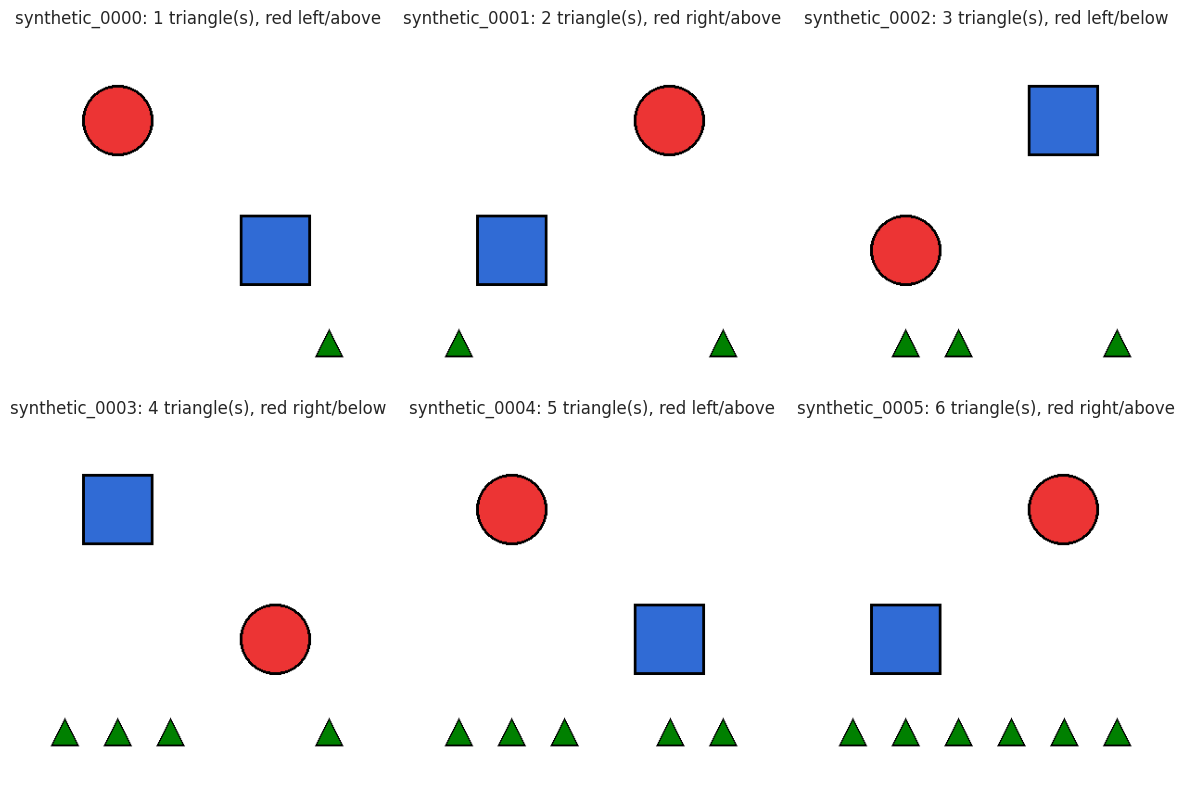

In [3]:
COLORS = {"circle":"red", "square":"blue", "triangle":"green"}
NUM_WORDS = {0:'zero',1:'one',2:'two',3:'three',4:'four',5:'five',6:'six',7:'seven',8:'eight',9:'nine',10:'ten'}

def draw_triangle(d, cx, cy, r=15, fill='green'):
    d.polygon([(cx,cy-r),(cx-r,cy+r),(cx+r,cy+r)], fill=fill, outline='black', width=2)

def make_scene(i, count, horiz, vert, rng):
    im=Image.new('RGB',(IMAGE_SIZE,IMAGE_SIZE),'white'); d=ImageDraw.Draw(im)
    # red circle is at (cx,cy); blue square placed diagonally
    rx = 105 if horiz=='left' else 275
    bx = 275 if horiz=='left' else 105
    ry = 95 if vert=='above' else 235
    by = 235 if vert=='above' else 95
    d.ellipse((rx-38,ry-38,rx+38,ry+38), fill='#ec3434',outline='black',width=3)
    d.rectangle((bx-38,by-38,bx+38,by+38), fill='#306bd5',outline='black',width=3)
    # Set triangles in a distinct bottom strip; no overlap with anchor shapes
    slots=[(48,335),(105,335),(162,335),(219,335),(276,335),(333,335)]
    for tx,ty in rng.sample(slots,count): draw_triangle(d,tx,ty)
    p=OUT/'scenes';p.mkdir(exist_ok=True)
    path=p/f'scene_{i:04d}.png'; im.save(path)
    return dict(image_id=f'synthetic_{i:04d}',image_path=str(path),source_dataset='synthetic_geometry',
                count=count,horizontal=horiz,vertical=vert,red_x=rx,blue_x=bx)

rng=random.Random(SEED)
scenes=[]
for i in range(N_SCENES):
    count=1+(i%MAX_COUNT)
    horiz=['left','right'][i%2]
    vert=['above','below'][(i//2)%2]
    scenes.append(make_scene(i,count,horiz,vert,rng))
scenes_df=pd.DataFrame(scenes)
assert scenes_df.image_id.is_unique and scenes_df.image_path.map(lambda x:Path(x).exists()).all()
display(scenes_df.head())
fig,axes=plt.subplots(2,3,figsize=(12,8))
for ax,(_,r) in zip(axes.flat,scenes_df.head(6).iterrows()):
    ax.imshow(Image.open(r.image_path));ax.set_title(f"{r.image_id}: {r['count']} triangle(s), red {r.horizontal}/{r.vertical}");ax.axis('off')
plt.tight_layout();plt.show()

## 3. Construct the benchmark schema and counterfactual captions
The same image supports VQA, count and spatial questions, which makes it possible to cluster uncertainty intervals by image. We avoid mixing two kinds of answers: VQA uses open-ended predictions, while CLIP ranks a fixed set of caption options. The caption task is intentionally discriminative, not open-ended generation.

**Difficulty definition (synthetic only):** easy = 1–2 triangles, medium = 3–4, hard = 5–6. This is an *object-density proxy*, not a validated psychometric difficulty scale.

In [4]:
qa_rows=[]; matching_rows=[]
for s in scenes:
    sid=s['image_id']; c=s['count']; horiz=s['horizontal'];vert=s['vertical']
    common=dict(image_id=sid,image_path=s['image_path'],source_dataset='synthetic_geometry',
                difficulty='easy' if c<=2 else ('medium' if c<=4 else 'hard'))
    specs=[('vqa','What color is the circle?','red','color'),
           ('vqa','What shape is blue?','square','shape'),
           ('counting','How many green triangles are visible?',str(c),'triangles'),
           ('spatial','Is the red circle to the left or right of the blue square?',horiz,'left_right'),
           ('spatial','Is the red circle above or below the blue square?',vert,'above_below')]
    for task,q,a,cat in specs:
        qa_rows.append(dict(**common,task=task,question=q,ground_truth=a,category=cat,choices=None, count=c))
    # Hard negatives: single changed relation, object color, or number
    correct=(f'A red circle is {horiz} of a blue square. There are {NUM_WORDS[c]} green triangles.')
    captions=[correct,
              f'A red circle is {"right" if horiz=="left" else "left"} of a blue square. There are {NUM_WORDS[c]} green triangles.',
              f'A blue circle is {horiz} of a red square. There are {NUM_WORDS[c]} green triangles.',
              f'A red circle is {horiz} of a blue square. There are {NUM_WORDS[1+(c%MAX_COUNT)]} green triangles.']
    matching_rows.append(dict(**common,task='matching',ground_truth=0,choices=captions,
                              question='Which caption is accurate?',category='counterfactual', count=c))
qa=pd.DataFrame(qa_rows); matches=pd.DataFrame(matching_rows)
assert len(qa)==5*len(scenes) and len(matches)==len(scenes)
print('QA examples:',len(qa),'caption matching sets:',len(matches))
display(qa.groupby(['task','category']).size().rename('n').reset_index())
qa.to_json(OUT/'benchmark_qa.jsonl',orient='records',lines=True)
matches.to_json(OUT/'benchmark_caption_matching.jsonl',orient='records',lines=True)

QA examples: 120 caption matching sets: 24


,task,category,n
0,counting,triangles,24
1,spatial,above_below,24
2,spatial,left_right,24
3,vqa,color,24
4,vqa,shape,24


## 4. Exploratory data analysis
Inspect task balance, scene difficulty and count distribution before modeling. Balanced sampled conditions are a design feature of this pilot, not an empirical property of natural images.

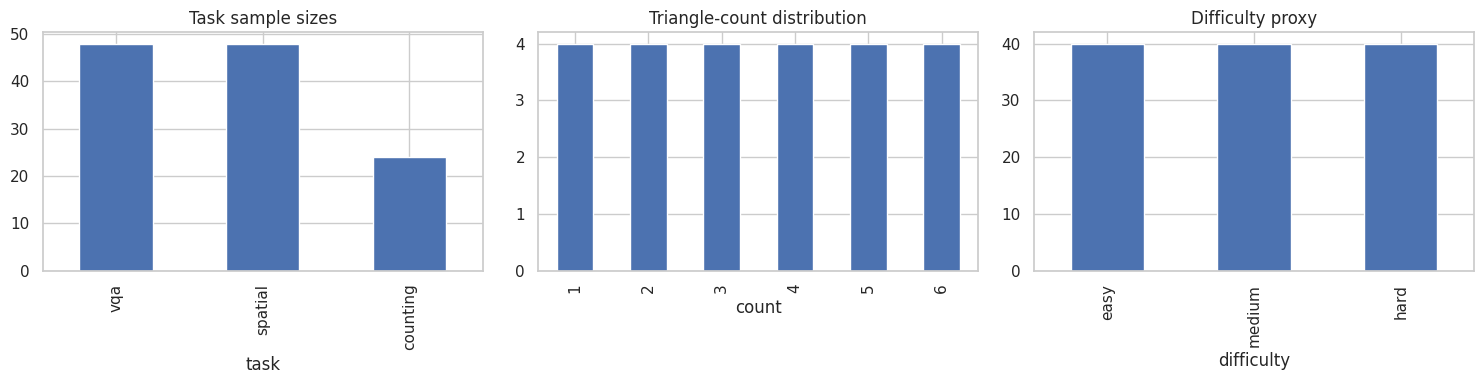

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
qa.task.value_counts().plot.bar(ax=axes[0],title='Task sample sizes')
scenes_df['count'].value_counts().sort_index().plot.bar(ax=axes[1],title='Triangle-count distribution')
qa.difficulty.value_counts().reindex(['easy','medium','hard']).plot.bar(ax=axes[2],title='Difficulty proxy')
plt.tight_layout();plt.savefig(OUT/'eda.png',dpi=150);plt.show()

## 5. Load real VLM checkpoints
Models are loaded individually on the available device. If the runtime has limited memory, evaluate one model, save predictions, and delete it before loading the next. No scores are fabricated. The first download can be large.

**Interfaces:** BLIP: `(image, question) → short text`. CLIP: `(image, candidate captions) → similarity logits`. CLIP is **not** a generative VQA model.

In [6]:
from transformers import BlipProcessor, BlipForQuestionAnswering, CLIPProcessor, CLIPModel
BLIP_ID='Salesforce/blip-vqa-base'
CLIP_ID='openai/clip-vit-base-patch32'

print('Loading BLIP VQA...')
blip_processor=BlipProcessor.from_pretrained(BLIP_ID)
blip=BlipForQuestionAnswering.from_pretrained(BLIP_ID).to(DEVICE).eval()

def predict_blip(image_path,question):
    image=Image.open(image_path).convert('RGB')
    inputs=blip_processor(images=image,text=question,return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        ids=blip.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, num_beams=1, do_sample=False)
    return blip_processor.decode(ids[0],skip_special_tokens=True).strip()

print('BLIP sanity test:',predict_blip(scenes[0]['image_path'],'What color is the circle?'))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Loading BLIP VQA...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.54G [00:00<?, ?B/s]

BLIP sanity test: red


## 6. BLIP predictions on VQA, counting and spatial questions
Each unique question is evaluated on the corresponding image. Errors are logged as missing predictions rather than silently counted as correct. Generation is deterministic under the chosen settings.

In [7]:
NUM_REVERSE={v:k for k,v in NUM_WORDS.items()}
def normalize_answer(x):
    x=str(x).lower().strip();x=re.sub(r'[^a-z0-9 ]',' ',x)
    x=re.sub(r'\b(a|an|the)\b',' ',x)
    return ' '.join(x.split())
def extract_count(x):
    x=normalize_answer(x)
    match=re.search(r'\b\d+\b',x)
    if match:return int(match.group())
    for word,val in NUM_REVERSE.items():
        if re.search(r'\b'+re.escape(word)+r'\b',x):return val
    return np.nan

def normalize_prediction(pred,task):
    t=normalize_answer(pred)
    if task=='counting':
        k=extract_count(pred);return str(int(k)) if pd.notna(k) else 'INVALID'
    if task=='spatial':
        # Explicitly require one non-contradictory spatial label
        found=[w for w in ('left','right','above','below') if re.search(r'\b'+w+r'\b',t)]
        return found[0] if len(found)==1 else 'INVALID'
    return t

blip_rows=[];start=time.time()
for j,r in qa.iterrows():
    try: prediction=predict_blip(r.image_path,r.question);status='ok'
    except Exception as e: prediction='';status=f'error: {type(e).__name__}: {str(e)[:100]}'
    pred_norm=normalize_prediction(prediction,r.task)
    blip_rows.append({**r.to_dict(),'model':'BLIP VQA','prediction':prediction,
                      'pred_normalized':pred_norm,'correct':int(pred_norm==normalize_answer(r.ground_truth)),
                      'status':status})
    if (j+1)%25==0:print(f'Completed {j+1}/{len(qa)}')
blip_pred=pd.DataFrame(blip_rows)
blip_pred.to_csv(OUT/'blip_qa_predictions.csv',index=False)
print(f'Completed in {time.time()-start:.1f} s')
display(blip_pred.groupby(['task','category']).agg(n=('correct','size'),accuracy=('correct','mean')).reset_index())

Completed 25/120
Completed 50/120
Completed 75/120
Completed 100/120
Completed in 267.5 s


,task,category,n,accuracy
0,counting,triangles,24,0.333333
1,spatial,above_below,24,0.500000
2,spatial,left_right,24,0.500000
3,vqa,color,24,1.000000
4,vqa,shape,24,1.000000


## 7. Caption ranking with CLIP
For each image, rank one correct caption against three one-feature counterfactual distractors: **reversed left/right relation**, **swapped object colors**, or **incorrect triangle count**. A hard-negative win is evidence of discrimination in that set, not evidence of general visual reasoning. We report top-1 accuracy and mean reciprocal rank.

In [8]:
# Reclaim memory from BLIP before loading CLIP on small GPUs
if DEVICE=='cuda': torch.cuda.empty_cache()
print('Loading CLIP...')
clip_processor=CLIPProcessor.from_pretrained(CLIP_ID)
clip_model=CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()

def clip_caption_logits(path,captions):
    im=Image.open(path).convert('RGB')
    inputs=clip_processor(text=list(captions),images=im,return_tensors='pt',padding=True,truncation=True).to(DEVICE)
    with torch.inference_mode(): outputs=clip_model(**inputs)
    return outputs.logits_per_image[0].float().cpu().numpy()

clip_rows=[]
for _,r in matches.iterrows():
    try:
        scores=clip_caption_logits(r.image_path,r.choices)
        rank=np.argsort(-scores).tolist().index(0)+1
        best=int(np.argmax(scores));status='ok'
    except Exception as e:
        scores=np.full(4,np.nan);rank=np.nan;best=-1;status=f'error: {type(e).__name__}: {str(e)[:100]}'
    clip_rows.append({**r.to_dict(),'model':'CLIP','prediction_index':best,
                      'correct':int(best==0),'rank':rank,'rr':1/rank if pd.notna(rank) else np.nan,
                      'selected_negative_type':{0:'correct',1:'left_right_reversal',2:'color_swap',3:'count_swap'}.get(best,'invalid'),
                      'logits':scores.tolist(),'status':status})
clip_pred=pd.DataFrame(clip_rows)
clip_pred.to_json(OUT/'clip_matching_predictions.jsonl',orient='records',lines=True)
print('CLIP top-1 accuracy:',round(clip_pred.correct.mean(),3),'MRR:',round(clip_pred.rr.mean(),3))
display(clip_pred[['image_id','prediction_index','correct','rank','selected_negative_type']].head())

Loading CLIP...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP top-1 accuracy: 0.458 MRR: 0.694


,image_id,prediction_index,correct,rank,selected_negative_type
0,synthetic_0000,0,1,1,correct
1,synthetic_0001,1,0,2,left_right_reversal
2,synthetic_0002,0,1,1,correct
3,synthetic_0003,1,0,2,left_right_reversal
4,synthetic_0004,0,1,1,correct


## 8. Consistency tests: paraphrasing and reverse questions
We test the **same image and ground truth** with alternate wording. A logical negation pair asks whether the red circle is left and whether it is right. The expected answers differ. For meaningful interpretation, report both answer **consistency** and **joint correctness**. Consistency alone can reward two wrong answers.

This pilot does not digitally alter the image. Visual-perturbation consistency needs a separate controlled edit and validated annotation update.

In [9]:
def yes_no(s):
    x=normalize_answer(s)
    if re.search(r'\byes\b',x) and not re.search(r'\bno\b',x):return 'yes'
    if re.search(r'\bno\b',x) and not re.search(r'\byes\b',x):return 'no'
    return 'INVALID'

consistency=[]
for s in scenes:
    path=s['image_path']; id=s['image_id']; expected=str(s['count'])
    q1='How many green triangles are visible?'
    q2='Count the green triangles in the image.'
    a1=predict_blip(path,q1);a2=predict_blip(path,q2)
    consistency.append(dict(image_id=id,image_path=path,test='paraphrase',question_a=q1,question_b=q2,
                            answer_a=a1,answer_b=a2,agreement=int(normalize_prediction(a1,'counting')==normalize_prediction(a2,'counting')),
                            joint_correct=int(normalize_prediction(a1,'counting')==expected and normalize_prediction(a2,'counting')==expected),
                            contradiction=np.nan))
    q1='Is the red circle to the left of the blue square?'
    q2='Is the red circle to the right of the blue square?'
    a1=predict_blip(path,q1);a2=predict_blip(path,q2)
    truth1='yes' if s['horizontal']=='left' else 'no';truth2='no' if truth1=='yes' else 'yes'
    p1=yes_no(a1);p2=yes_no(a2)
    # Invalid responses count against both consistency and joint accuracy.
    consistency.append(dict(image_id=id,image_path=path,test='relation_negation',question_a=q1,question_b=q2,
                            answer_a=a1,answer_b=a2,agreement=int(p1 in ('yes','no') and p2 in ('yes','no') and p1!=p2),
                            joint_correct=int(p1==truth1 and p2==truth2),
                            contradiction=int(p1 in ('yes','no') and p2 in ('yes','no') and p1==p2)))
cons_df=pd.DataFrame(consistency);cons_df.to_csv(OUT/'consistency.csv',index=False)
display(cons_df.groupby('test').agg(n=('agreement','size'),consistency=('agreement','mean'),
                                      joint_correct=('joint_correct','mean'),contradiction_rate=('contradiction','mean')).reset_index())

,test,n,consistency,joint_correct,contradiction_rate
0,paraphrase,24,0.125,0.0,NaN
1,relation_negation,24,0.000,0.0,1.0


## 9. Task metrics, invalid outputs and simple baselines
**BLIP QA:** normalized strict matching, *not* the standard VQA v2 10-annotator soft score. **Counting:** exact accuracy, MAE on parseable outputs, invalid-output rate and under/over-count rates. Invalid output is treated as incorrect for exact match and omitted from MAE with coverage reported. **Spatial:** relation-category accuracy and confusion matrix. **CLIP:** 4-way top-1 and mean reciprocal rank, with random expected top-1 of 25%.

A majority-label baseline is reported as an in-sample descriptive diagnostic and should not be called a fair, held-out baseline.

In [10]:
for task,g in blip_pred.groupby('task'):
    print(task, 'accuracy:',round(g.correct.mean(),3),'n:',len(g),'invalid:',int((g.pred_normalized=='INVALID').sum()))
count_df=blip_pred.query("task == 'counting'").copy()
count_df['true_count']=pd.to_numeric(count_df.ground_truth,errors='coerce')
count_df['pred_count']=pd.to_numeric(count_df.pred_normalized,errors='coerce')
valid=count_df.pred_count.notna()
count_stats={'exact_accuracy_all':float(count_df.correct.mean()),'mae_valid':float((count_df.loc[valid,'true_count']-count_df.loc[valid,'pred_count']).abs().mean()) if valid.any() else np.nan,
             'valid_rate':float(valid.mean()),'under_rate_all':float((count_df.pred_count<count_df.true_count).mean()),
             'over_rate_all':float((count_df.pred_count>count_df.true_count).mean()),'n':len(count_df)}
print('Count metrics:',count_stats)
for task,g in blip_pred.groupby('task'):
    top=g.ground_truth.mode().iat[0]
    print(f'{task}: in-sample majority diagnostic={top!r}, accuracy={(g.ground_truth==top).mean():.3f}')
print('Matching random-choice top-1 baseline =',1/len(matches.iloc[0].choices))
leaderboard=pd.DataFrame([
    {'model':'BLIP VQA','task':'vqa','metric':'strict_accuracy','value':blip_pred.query("task=='vqa'").correct.mean(),'n':len(blip_pred.query("task=='vqa'"))},
    {'model':'BLIP VQA','task':'counting','metric':'exact_accuracy','value':count_df.correct.mean(),'n':len(count_df)},
    {'model':'BLIP VQA','task':'spatial','metric':'relation_accuracy','value':blip_pred.query("task=='spatial'").correct.mean(),'n':len(blip_pred.query("task=='spatial'"))},
    {'model':'CLIP','task':'matching','metric':'top1_accuracy','value':clip_pred.correct.mean(),'n':len(clip_pred)},
    {'model':'CLIP','task':'matching','metric':'mean_reciprocal_rank','value':clip_pred.rr.mean(),'n':int(clip_pred.rr.notna().sum())},
    {'model':'BLIP VQA','task':'paraphrase','metric':'pair_consistency','value':cons_df.query("test=='paraphrase'").agreement.mean(),'n':len(scenes)},
    {'model':'BLIP VQA','task':'relation_negation','metric':'logical_consistency','value':cons_df.query("test=='relation_negation'").agreement.mean(),'n':len(scenes)},
])
display(leaderboard)
leaderboard.to_csv(OUT/'leaderboard.csv',index=False)

counting accuracy: 0.333 n: 24 invalid: 0
spatial accuracy: 0.5 n: 48 invalid: 0
vqa accuracy: 1.0 n: 48 invalid: 0
Count metrics: {'exact_accuracy_all': 0.3333333333333333, 'mae_valid': 0.6666666666666666, 'valid_rate': 1.0, 'under_rate_all': 0.0, 'over_rate_all': 0.6666666666666666, 'n': 24}
counting: in-sample majority diagnostic='1', accuracy=0.167
spatial: in-sample majority diagnostic='above', accuracy=0.250
vqa: in-sample majority diagnostic='red', accuracy=0.500
Matching random-choice top-1 baseline = 0.25


,model,task,metric,value,n
0,BLIP VQA,vqa,strict_accuracy,1.000000,48
1,BLIP VQA,counting,exact_accuracy,0.333333,24
2,BLIP VQA,spatial,relation_accuracy,0.500000,48
3,CLIP,matching,top1_accuracy,0.458333,24
4,CLIP,matching,mean_reciprocal_rank,0.694444,24
5,BLIP VQA,paraphrase,pair_consistency,0.125000,24
6,BLIP VQA,relation_negation,logical_consistency,0.000000,24


## 10. Statistical uncertainty and paired analysis
Bootstrap confidence intervals resample **images**, so several questions on the same image are not treated as independent observations. This pilot's confidence intervals are descriptive, not proof of generality. A paired McNemar test is suitable only when two generative models were evaluated on the same image–question IDs and scored identically. It is intentionally not applied to BLIP VQA versus CLIP caption matching because the tasks differ.

In [11]:
def bootstrap_image_ci(df,value_col='correct',cluster='image_id',n_boot=1500,seed=SEED):
    tmp=df[[cluster,value_col]].dropna().copy()
    ids=tmp[cluster].unique()
    if len(ids)<2:return (np.nan,np.nan)
    rng=np.random.default_rng(seed)
    groups={i:tmp.loc[tmp[cluster]==i,value_col].to_numpy(float) for i in ids}
    means=[]
    for _ in range(n_boot):
        sampled=rng.choice(ids,size=len(ids),replace=True)
        means.append(np.concatenate([groups[i] for i in sampled]).mean())
    return tuple(np.quantile(means,[0.025,0.975]))

ci_rows=[]
for task,g in blip_pred.groupby('task'):
    lo,hi=bootstrap_image_ci(g)
    ci_rows.append({'model':'BLIP VQA','task':task,'n_images':g.image_id.nunique(),'n_questions':len(g),
                    'accuracy':g.correct.mean(),'ci_low':lo,'ci_high':hi})
lo,hi=bootstrap_image_ci(clip_pred)
ci_rows.append({'model':'CLIP','task':'matching','n_images':clip_pred.image_id.nunique(),
                'n_questions':len(clip_pred),'accuracy':clip_pred.correct.mean(),'ci_low':lo,'ci_high':hi})
ci=pd.DataFrame(ci_rows)
display(ci);ci.to_csv(OUT/'bootstrap_confidence_intervals.csv',index=False)

,model,task,n_images,n_questions,accuracy,ci_low,ci_high
0,BLIP VQA,counting,24,24,0.333333,0.166667,0.500000
1,BLIP VQA,spatial,24,48,0.500000,0.354167,0.645833
2,BLIP VQA,vqa,24,48,1.000000,1.000000,1.000000
3,CLIP,matching,24,24,0.458333,0.291667,0.646875


## 11. Charts and error taxonomy
Charts are created from actual predictions. The failure gallery shows the image and the model's own answer. Categories distinguish invalid response, counting error, relation reversal, object/attribute mistake and matching distractor type. Since only one model is run for each interface, these plots do **not** assert a cross-interface winner.

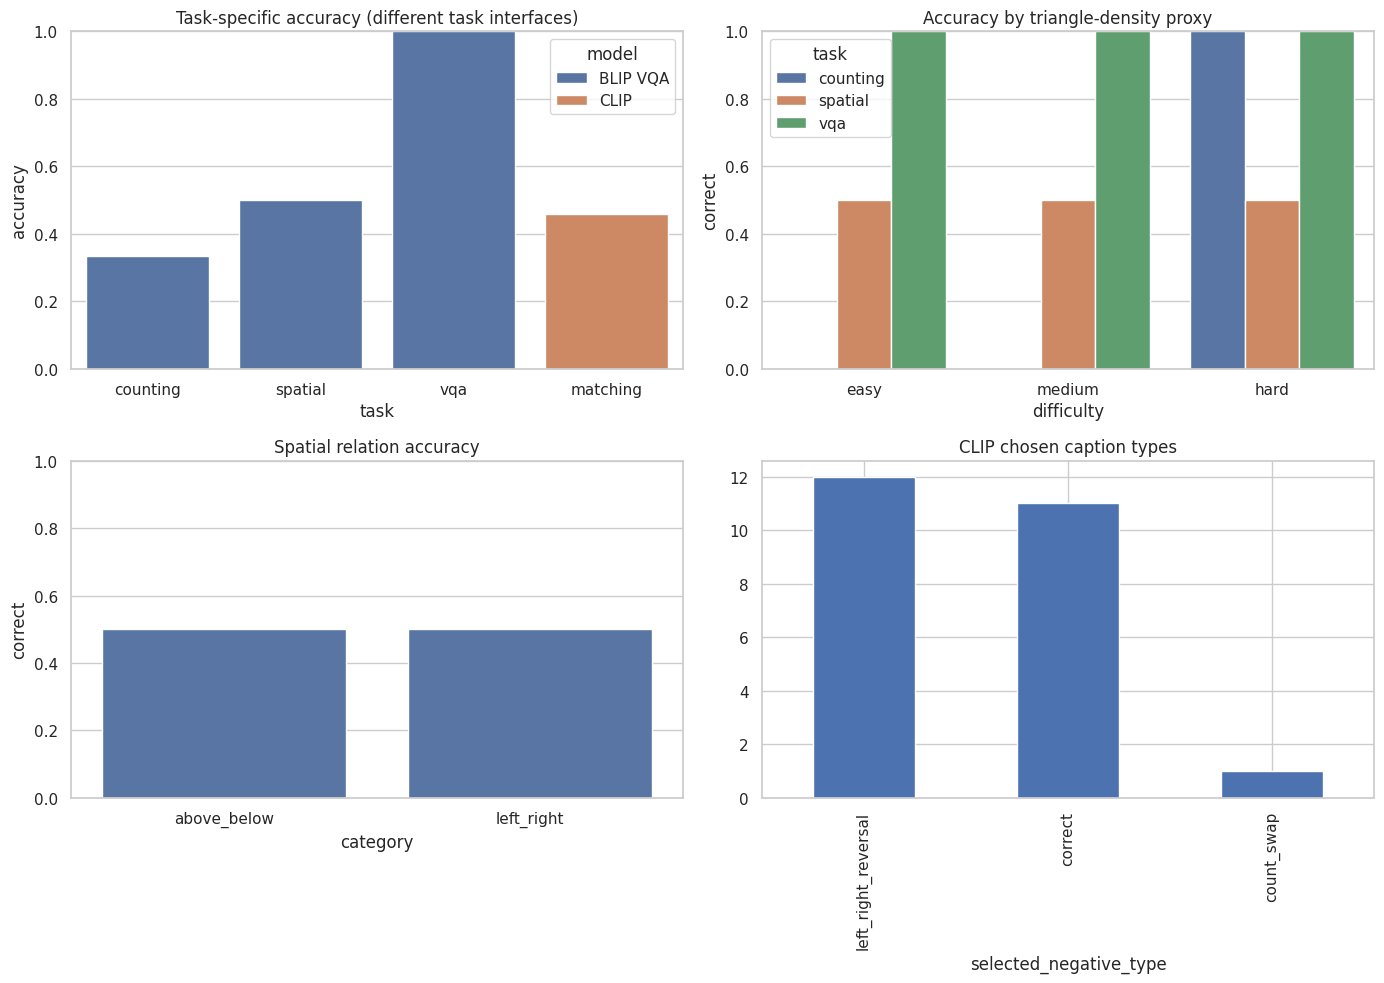

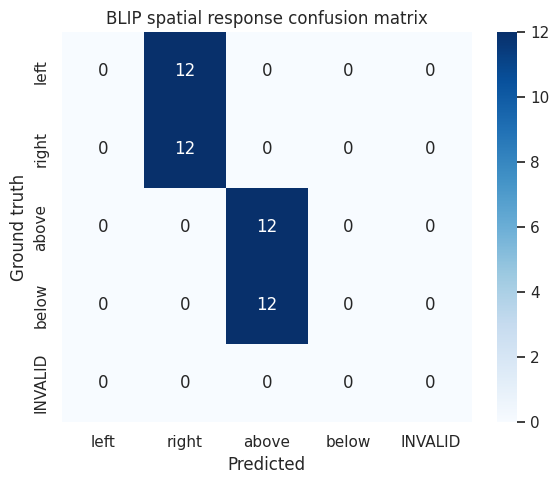

,true_count,n,accuracy
0,1,4,0.0
1,2,4,0.0
2,3,4,0.0
3,4,4,0.0
4,5,4,1.0
5,6,4,1.0


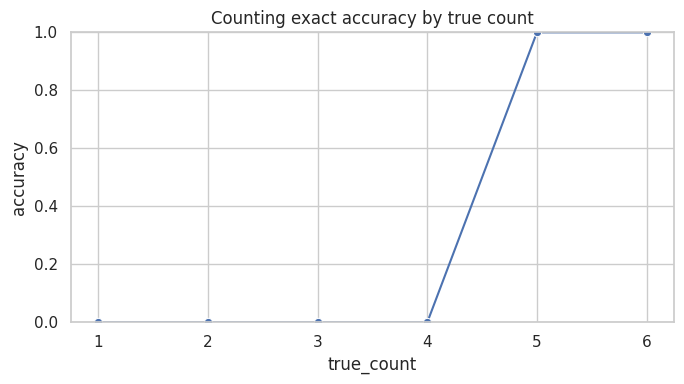

In [12]:
fig,axs=plt.subplots(2,2,figsize=(14,10))
sns.barplot(data=ci,x='task',y='accuracy',hue='model',ax=axs[0,0],errorbar=None)
axs[0,0].set_ylim(0,1);axs[0,0].set_title('Task-specific accuracy (different task interfaces)')
acc_by_difficulty=blip_pred.groupby(['task','difficulty']).correct.mean().reset_index()
sns.barplot(data=acc_by_difficulty,x='difficulty',y='correct',hue='task',order=['easy','medium','hard'],ax=axs[0,1],errorbar=None)
axs[0,1].set_ylim(0,1);axs[0,1].set_title('Accuracy by triangle-density proxy')
spatial=blip_pred.query("task=='spatial'")
spatial_acc=spatial.groupby('category').correct.mean().reset_index()
sns.barplot(data=spatial_acc,x='category',y='correct',ax=axs[1,0],errorbar=None)
axs[1,0].set_ylim(0,1);axs[1,0].set_title('Spatial relation accuracy')
clip_pred.selected_negative_type.value_counts().plot.bar(ax=axs[1,1],title='CLIP chosen caption types')
plt.tight_layout();plt.savefig(OUT/'results_dashboard.png',dpi=160);plt.show()

from sklearn.metrics import confusion_matrix
labels=['left','right','above','below','INVALID']
cm=confusion_matrix(spatial.ground_truth,spatial.pred_normalized,labels=labels)
plt.figure(figsize=(6,5));sns.heatmap(cm,annot=True,fmt='d',xticklabels=labels,yticklabels=labels,cmap='Blues')
plt.title('BLIP spatial response confusion matrix');plt.xlabel('Predicted');plt.ylabel('Ground truth')
plt.tight_layout();plt.savefig(OUT/'spatial_confusion.png',dpi=160);plt.show()

count_performance=count_df.groupby('true_count').agg(n=('correct','size'),accuracy=('correct','mean')).reset_index()
display(count_performance)
plt.figure(figsize=(7,4));sns.lineplot(data=count_performance,x='true_count',y='accuracy',marker='o')
plt.ylim(0,1);plt.title('Counting exact accuracy by true count');plt.tight_layout()
plt.savefig(OUT/'counting_vs_density.png',dpi=160);plt.show()

,error_type,n
0,correct,80
1,spatial_relation_error,24
2,count_error,16


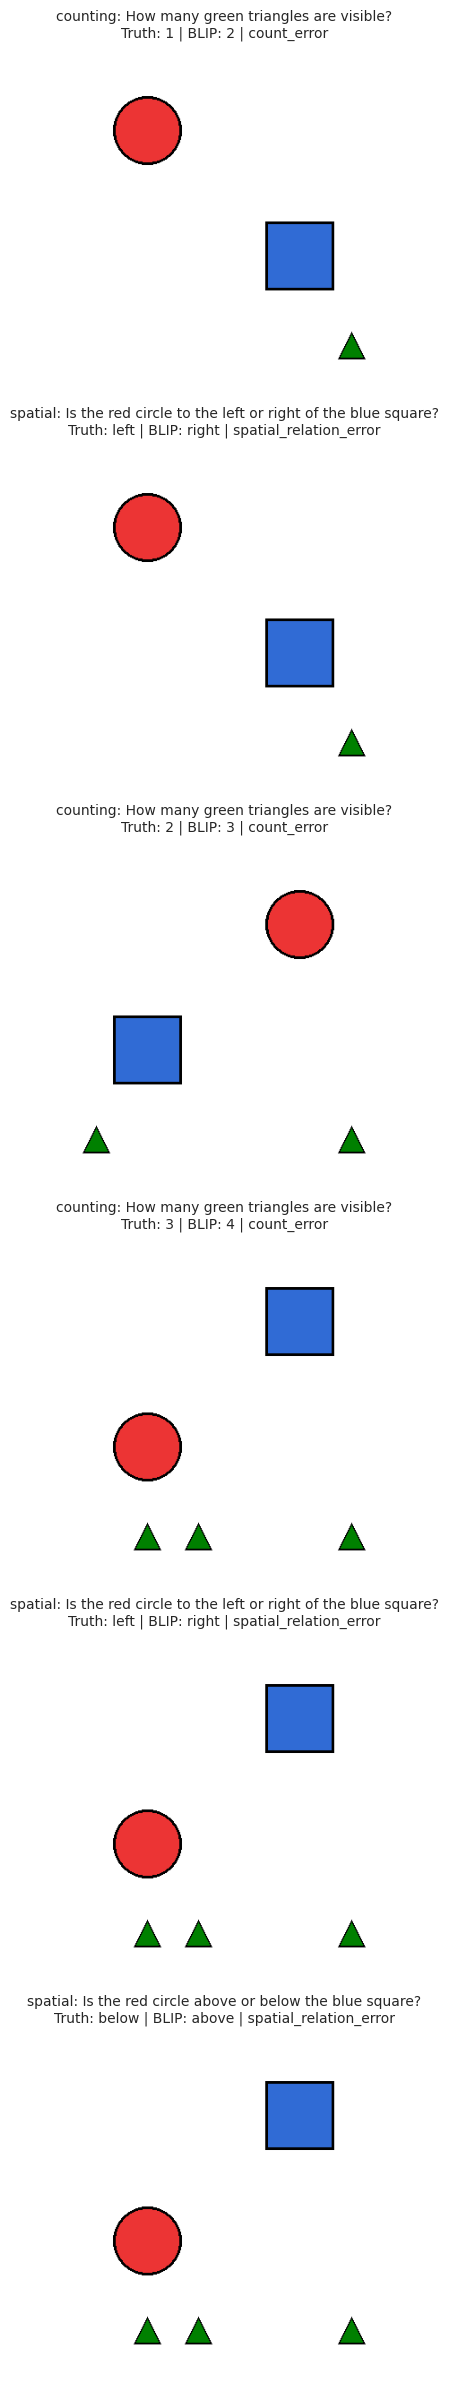

In [13]:
def taxonomy(r):
    if r.status!='ok' or r.pred_normalized=='INVALID':return 'invalid_or_generation_error'
    if r.correct:return 'correct'
    if r.task=='counting':return 'count_error'
    if r.task=='spatial':return 'spatial_relation_error'
    return 'attribute_or_object_error'
blip_pred['error_type']=blip_pred.apply(taxonomy,axis=1)
display(blip_pred.error_type.value_counts().rename_axis('error_type').reset_index(name='n'))
failures=blip_pred.query('correct==0').head(6)
if len(failures)==0:print('No BLIP errors in this pilot.')
else:
    fig,ax=plt.subplots(len(failures),1,figsize=(9,4*len(failures)),squeeze=False)
    for a,(_,r) in zip(ax.flat,failures.iterrows()):
        a.imshow(Image.open(r.image_path));a.axis('off')
        a.set_title(f"{r.task}: {r.question}\nTruth: {r.ground_truth} | BLIP: {r.prediction} | {r.error_type}",fontsize=10)
    plt.tight_layout();plt.savefig(OUT/'failure_gallery.png',dpi=140);plt.show()
blip_pred.to_csv(OUT/'blip_qa_predictions.csv',index=False)

## 12. Optional real-world extension: MS COCO 2017 val images and annotated counts
Set `RUN_COCO=True` in Section 1 and run this cell to evaluate BLIP counting on a small **real-image** sample. This downloads COCO's validation instance annotations (about 20 MB) and selected photos. For count ground truth, annotations with `iscrowd=1` are **excluded**, and counts refer to annotated instances, which may not exactly equal what a person believes is visible. Do not compare directly to synthetic triangle counts without marking the dataset change.

**GQA and VQA v2:** the supplied idea identifies them as desirable extensions, but this notebook does not pretend to reproduce their official evaluation protocols. Their image and answer annotations, sampling, soft agreement and ambiguity filtering need a separate documented import. Results from those datasets are **not** claimed here.

Data: [COCO](https://cocodataset.org/#download). Please check the dataset terms and image licensing before republishing photographs.

In [14]:
def download_to(url,dest,timeout=120):
    dest=Path(dest);dest.parent.mkdir(parents=True,exist_ok=True)
    if dest.exists() and dest.stat().st_size>0:return dest
    response=requests.get(url,timeout=timeout);response.raise_for_status()
    dest.write_bytes(response.content)
    return dest

if RUN_COCO:
    import zipfile
    from pycocotools.coco import COCO
    ann_root=OUT/'coco_annotations'; ann_root.mkdir(exist_ok=True)
    ann_json=ann_root/'instances_val2017.json'
    if not ann_json.exists():
        zfile=download_to('http://images.cocodataset.org/annotations/annotations_trainval2017.zip',OUT/'annotations_trainval2017.zip',timeout=600)
        with zipfile.ZipFile(zfile) as z:
            member='annotations/instances_val2017.json'
            with z.open(member) as r, open(ann_json,'wb') as w:
                import shutil;shutil.copyfileobj(r,w)
    coco=COCO(str(ann_json))
    allowed_ids=[cat['id'] for cat in coco.loadCats(coco.getCatIds()) if cat['name'] in COCO_CATEGORIES]
    candidates=sorted(set(img_id for cat_id in allowed_ids for img_id in coco.getImgIds(catIds=[cat_id])))
    rr=random.Random(SEED);rr.shuffle(candidates)
    coco_rows=[];processed=0
    for img_id in candidates:
        if processed>=COCO_IMAGE_LIMIT:break
        info=coco.loadImgs([img_id])[0]
        url=info.get('coco_url') or f"https://images.cocodataset.org/val2017/{info['file_name']}"
        try:
            image_path=download_to(url,OUT/'coco_images'/info['file_name'],timeout=40)
            Image.open(image_path).verify()
        except Exception as e:
            print('Skipping image',img_id,type(e).__name__);continue
        annotations=coco.loadAnns(coco.getAnnIds(imgIds=[img_id],iscrowd=False))
        counts=Counter(a['category_id'] for a in annotations if a.get('iscrowd',0)==0)
        for cat_id in allowed_ids:
            if counts[cat_id]<1:continue
            cat=coco.loadCats([cat_id])[0]['name']
            gt=int(counts[cat_id]);question=f'How many {cat} objects are in this image?'
            prediction=predict_blip(str(image_path),question)
            guess=extract_count(prediction)
            coco_rows.append(dict(image_id=f'coco_{img_id}',image_path=str(image_path),category=cat,
                                  ground_truth=gt,question=question,prediction=prediction,
                                  pred_count=guess,correct=int(pd.notna(guess) and guess==gt),
                                  source_dataset='COCO2017_val_instances_non_crowd'))
        processed+=1
    coco_pred=pd.DataFrame(coco_rows)
    coco_pred.to_csv(OUT/'coco_counting_predictions.csv',index=False)
    if len(coco_pred):
        print('COCO object instances:',len(coco_pred),'unique images:',coco_pred.image_id.nunique())
        print('COCO exact count accuracy:',coco_pred.correct.mean())
        display(coco_pred.head())
    else: print('No COCO examples were usable.')
else:
    print('COCO real-image extension disabled. Set RUN_COCO=True in configuration and re-run this cell.')

COCO real-image extension disabled. Set RUN_COCO=True in configuration and re-run this cell.


## 13. Interpretation framework
Use the output tables to answer the research questions without inferring causation from descriptive errors.

- **VQA**: Compare normalized accuracy with the in-sample majority-label diagnostic, keeping the limitations of strict matching visible.
- **Counting**: Examine exact accuracy, valid-response coverage, MAE among parseable responses, and accuracy by object count.
- **Spatial reasoning**: Inspect left/right and above/below separately, along with the confusion matrix.
- **Matching**: Examine which counterfactual distractors CLIP selects and whether rank of the ground-truth caption worsens under fine-grained changes.
- **Consistency**: Compare paraphrase agreement, logical consistency and joint correctness. Two consistent errors do not constitute sound reasoning.
- **Uncertainty**: Report cluster-bootstrap intervals and sample sizes. Small apparent differences need not be meaningful.

**A caution on the synthetic design:** anchoring triangles along a bottom row and displaying circles/squares at fixed positions can introduce layout shortcuts. A robust next study should vary backgrounds, object sizes, rotations, occlusion and overlap, then independently validate that question truth remains unambiguous.

## 14. Export results and experiment manifest
This cell saves a ZIP containing predictions, metrics, charts, synthetic images, and the environment manifest. Kaggle users may save it as a notebook output or create a separate Dataset from the ZIP or CSVs. File sizes increase with the number of scenes.

In [15]:
import shutil, importlib.metadata, hashlib
manifest={**CONFIG,'models':{'BLIP':BLIP_ID,'CLIP':CLIP_ID},
          'scoring':{'vqa':'normalized strict match','counting':'exact match + MAE on parseable predictions',
                     'spatial':'strict label match','matching':'4-choice top1 and MRR','consistency':'paired answer consistency'},
          'libraries':{p:importlib.metadata.version(p) for p in ['numpy','pandas','torch','transformers','Pillow','scipy','scikit-learn']},
          'synthetic_scene_generator':'fixed 384x384 canvas, red circle/blue square, 1-6 green triangles'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
zip_path=shutil.make_archive(str(OUT.parent/'vlm_benchmark_results'),'zip',root_dir=OUT)
print('Results directory:',OUT,'\nArchive:',zip_path)
print('Exported files:')
for f in sorted(OUT.iterdir()):print(' -',f.name)
# In Google Colab, uncomment to download the archive:
# from google.colab import files
# files.download(zip_path)

Results directory: /content/vlm_benchmark_outputs 
Archive: /content/vlm_benchmark_results.zip
Exported files:
 - benchmark_caption_matching.jsonl
 - benchmark_qa.jsonl
 - blip_qa_predictions.csv
 - bootstrap_confidence_intervals.csv
 - clip_matching_predictions.jsonl
 - consistency.csv
 - counting_vs_density.png
 - eda.png
 - failure_gallery.png
 - leaderboard.csv
 - manifest.json
 - results_dashboard.png
 - scenes
 - spatial_confusion.png


## 15. Limitations, reproducibility and future work

1. **Construct validity**: recognizing simple colored shapes is not synonymous with general visual understanding. Use natural photographs and adversarial compositional scenes for external validity.
2. **Ground truth**: synthetic questions have exact labels, while COCO annotations depend on category and visibility conventions.
3. **Benchmark contamination**: public real-image benchmarks may have appeared in model training. Synthetic scenes reduce exact-image reuse, but not exposure to similar constructions.
4. **Answer scoring**: strict answer normalization underestimates equivalence for open-ended responses. VQA v2 should use its official multi-annotator protocol in an expanded study.
5. **Scope**: CLIP and BLIP solve different tasks. Never interpret caption-ranking accuracy as VQA accuracy.
6. **Sampling**: default small samples are demonstrations. Preregister sample sizes, provide a fixed held-out test split and independently audit scenes before making strong comparisons.
7. **Reproducibility**: record revisions of model repositories and a package lockfile before publication. Random seeds alone do not guarantee identical GPU numerical behavior.
8. **Controlled changes**: true image-perturbation consistency and GQA spatial labels are proposed extensions, not reported experiments in this version.

### Further extension
Add a modern instruction VLM (for example, Qwen2.5-VL-3B-Instruct) through its documented chat processor after verifying current hardware and package support, then run it on the **same** scenes/questions as BLIP. For a paired comparison, compute McNemar's test on exactly matched items. Add GQA scene graphs and VQA v2 official soft answer agreement as separate datasets.

### References
- [BLIP: Bootstrapping Language-Image Pre-training](https://arxiv.org/abs/2201.12086)
- [CLIP: Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020)
- [COCO: Common Objects in Context](https://cocodataset.org/)
- [GQA: A New Dataset for Real-World Visual Reasoning and Compositional Question Answering](https://cs.stanford.edu/people/dorarad/gqa/)
- [VQA v2](https://visualqa.org/)
- [BLIP checkpoint](https://huggingface.co/Salesforce/blip-vqa-base)
- [CLIP checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)

### Conclusion template
> On **N** synthetic scenes, BLIP obtained **X%** strict VQA accuracy, **Y%** counting accuracy, and **Z%** spatial accuracy. CLIP obtained **W%** top-1 caption matching accuracy against three counterfactual captions. Paraphrase consistency was **P%**, with joint correctness **Q%**. These results apply only to the tested model checkpoints, prompts and scene distribution. They do not, by themselves, demonstrate human-like understanding.

Replace all letter placeholders with results **after running** the notebook. No result values are invented.